# Phase 4 Hybrid Model

This notebook trains hybrid fake review detection models by combining metadata, linguistic, product, and seller context features.

The purpose of this phase is to evaluate whether combining multiple feature groups improves fake review detection compared with baseline only and linguistic only models.

Models used:
- Logistic Regression
- Random Forest

Evaluation metrics:
- Accuracy
- Precision
- Recall
- F1 score
- Confusion Matrix

Important:
- The same 80/20 stratified train/test split is used for fair comparison.
- Leakage and identifier columns are removed before training.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

sns.set_theme(style="whitegrid")

# Create output folder
os.makedirs("outputs", exist_ok=True)


## 1. Load Dataset

This phase uses the shared clean modelling dataset generated after Phase 2. If the path is different on your machine, update `DATA_PATH`.


In [2]:
# Try common dataset paths
possible_paths = [
    "../phase2/clean_model_dataset.csv",
    "../phase1/clean_model_dataset.csv",
    "../phase1/final_dataset.csv",
    "../phase2/final_dataset.csv",
    "clean_model_dataset.csv"
]

DATA_PATH = None

for path in possible_paths:
    if os.path.exists(path):
        DATA_PATH = path
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Please update DATA_PATH to the location of clean_model_dataset.csv."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded from:", DATA_PATH)
print("Dataset shape:", df.shape)

df.head()


Dataset loaded from: ../phase2/clean_model_dataset.csv
Dataset shape: (100000, 58)


,review_id,product_id,user_id,review_date,year,month,star_rating,sentiment,verified_purchase,is_fake_review,review_length_words,has_title,title_word_count,num_images_attached,helpful_votes,total_votes,helpful_ratio,days_since_purchase,reviewer_review_count,is_top_reviewer,is_early_review,exclamation_marks,all_caps_ratio,readability_score,category,price_usd,price_tier,brand_tier,sent_star_rating,sentiment_label,sentiment_score,quality_aspect,shipping_aspect,value_aspect,service_aspect,emotion,is_sarcastic,subjectivity_score,polarity_score,seller_id,true_quality,is_prime,product_num_images,bullet_points,has_video,days_on_platform,product_total_reviews,product_avg_rating,n_products,avg_product_rating,seller_total_reviews,avg_star,fake_rate,verified_rate,years_on_platform,ships_internationally,avg_shipping_days,return_rate_pct
0,R00000001,P000873,U009862,2024-01-21,2024,1,5,positive,1,0,34,1,3,0,18,19,0.947,7,38,1,0,1,0.001,49.2,Automotive,91.13,mid,mid,5,positive,1.000,positive,positive,positive,neutral,delight,0,0.507,0.796,S0173,4.58,1,1,7,0,1699,53,3.93,8,3.24,129,3.57,0.0078,0.721,4,1,5.4,4.3
1,R00000002,P002733,U037196,2024-10-07,2024,10,4,positive,1,0,62,1,11,0,1,2,0.500,7,6,0,0,0,0.073,81.4,Books,14.12,budget,premium,4,positive,0.701,neutral,neutral,positive,positive,satisfaction,0,0.887,0.441,S0122,4.32,0,2,5,0,1655,36,3.96,15,3.31,319,3.75,0.0627,0.727,4,0,3.4,11.4
2,R00000003,P002589,U034741,2024-03-01,2024,3,5,positive,1,0,104,0,0,0,2,2,1.000,21,38,1,0,1,0.015,68.2,Home & Kitchen,91.03,mid,budget,5,positive,1.000,positive,positive,positive,positive,satisfaction,0,0.837,0.836,S0453,4.31,0,7,5,0,451,17,4.08,6,3.17,120,3.50,0.0417,0.750,5,0,2.3,8.7
3,R00000004,P001303,U037748,2024-03-23,2024,3,5,positive,1,0,92,1,10,0,32,41,0.780,30,42,1,0,2,0.078,97.5,Beauty,46.51,low,mid,5,positive,0.960,positive,positive,positive,positive,satisfaction,0,0.799,0.891,S0108,4.25,0,7,6,0,1632,43,3.62,14,3.14,275,3.69,0.0436,0.727,5,1,5.2,3.8
4,R00000005,P002439,U035906,2022-01-28,2022,1,3,neutral,1,1,110,1,6,5,8,12,0.667,15,44,1,0,6,0.323,41.4,Home & Kitchen,49.67,low,premium,3,neutral,0.031,neutral,neutral,negative,positive,neutral,0,0.978,0.116,S0382,4.22,0,1,6,1,1318,298,3.84,15,3.03,288,3.38,0.0729,0.760,7,0,3.5,12.0


## 2. Basic Data Checks

Before training, we check missing values, duplicated rows, and target distribution.


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(20))

print("\nDuplicated rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["is_fake_review"].value_counts())
display((df["is_fake_review"].value_counts(normalize=True) * 100).round(2))


Columns:
['review_id', 'product_id', 'user_id', 'review_date', 'year', 'month', 'star_rating', 'sentiment', 'verified_purchase', 'is_fake_review', 'review_length_words', 'has_title', 'title_word_count', 'num_images_attached', 'helpful_votes', 'total_votes', 'helpful_ratio', 'days_since_purchase', 'reviewer_review_count', 'is_top_reviewer', 'is_early_review', 'exclamation_marks', 'all_caps_ratio', 'readability_score', 'category', 'price_usd', 'price_tier', 'brand_tier', 'sent_star_rating', 'sentiment_label', 'sentiment_score', 'quality_aspect', 'shipping_aspect', 'value_aspect', 'service_aspect', 'emotion', 'is_sarcastic', 'subjectivity_score', 'polarity_score', 'seller_id', 'true_quality', 'is_prime', 'product_num_images', 'bullet_points', 'has_video', 'days_on_platform', 'product_total_reviews', 'product_avg_rating', 'n_products', 'avg_product_rating', 'seller_total_reviews', 'avg_star', 'fake_rate', 'verified_rate', 'years_on_platform', 'ships_internationally', 'avg_shipping_days', '

review_id                0
product_id               0
user_id                  0
review_date              0
year                     0
month                    0
star_rating              0
sentiment                0
verified_purchase        0
is_fake_review           0
review_length_words      0
has_title                0
title_word_count         0
num_images_attached      0
helpful_votes            0
total_votes              0
helpful_ratio            0
days_since_purchase      0
reviewer_review_count    0
is_top_reviewer          0
dtype: int64


Duplicated rows: 0

Target distribution:


is_fake_review
0    94100
1     5900
Name: count, dtype: int64

is_fake_review
0    94.1
1     5.9
Name: proportion, dtype: float64

## 3. Remove Leakage and Identifier Columns

The hybrid model should not use identifiers or leakage related features. These fields are removed before training.

We found that:
- `fake_confidence_score` and `sent_is_fake_review` should not be used if they exist.
- ID columns are removed because they do not generalise to unseen data.


In [4]:
# Columns that should not be used for model training
drop_cols = [
    # identifiers
    "review_id",
    "product_id",
    "user_id",
    "seller_id",
    "review_date",
    "period",

    # direct leakage columns
    "fake_confidence_score",
    "sent_is_fake_review",

    # high-risk proxy / synthetic generation related features
    "fake_rate",
    "sent_star_rating",
    "true_quality",

    # overly deterministic style features
    "all_caps_ratio",
    "exclamation_marks"
]

df_model = df.drop(columns=drop_cols, errors="ignore").copy()

print("Shape after dropping leakage/ID/proxy columns:", df_model.shape)

assert "is_fake_review" in df_model.columns, "Target column is_fake_review is missing."

df_model.head()

Shape after dropping leakage/ID/proxy columns: (100000, 48)


,year,month,star_rating,sentiment,verified_purchase,is_fake_review,review_length_words,has_title,title_word_count,num_images_attached,helpful_votes,total_votes,helpful_ratio,days_since_purchase,reviewer_review_count,is_top_reviewer,is_early_review,readability_score,category,price_usd,price_tier,brand_tier,sentiment_label,sentiment_score,quality_aspect,shipping_aspect,value_aspect,service_aspect,emotion,is_sarcastic,subjectivity_score,polarity_score,is_prime,product_num_images,bullet_points,has_video,days_on_platform,product_total_reviews,product_avg_rating,n_products,avg_product_rating,seller_total_reviews,avg_star,verified_rate,years_on_platform,ships_internationally,avg_shipping_days,return_rate_pct
0,2024,1,5,positive,1,0,34,1,3,0,18,19,0.947,7,38,1,0,49.2,Automotive,91.13,mid,mid,positive,1.000,positive,positive,positive,neutral,delight,0,0.507,0.796,1,1,7,0,1699,53,3.93,8,3.24,129,3.57,0.721,4,1,5.4,4.3
1,2024,10,4,positive,1,0,62,1,11,0,1,2,0.500,7,6,0,0,81.4,Books,14.12,budget,premium,positive,0.701,neutral,neutral,positive,positive,satisfaction,0,0.887,0.441,0,2,5,0,1655,36,3.96,15,3.31,319,3.75,0.727,4,0,3.4,11.4
2,2024,3,5,positive,1,0,104,0,0,0,2,2,1.000,21,38,1,0,68.2,Home & Kitchen,91.03,mid,budget,positive,1.000,positive,positive,positive,positive,satisfaction,0,0.837,0.836,0,7,5,0,451,17,4.08,6,3.17,120,3.50,0.750,5,0,2.3,8.7
3,2024,3,5,positive,1,0,92,1,10,0,32,41,0.780,30,42,1,0,97.5,Beauty,46.51,low,mid,positive,0.960,positive,positive,positive,positive,satisfaction,0,0.799,0.891,0,7,6,0,1632,43,3.62,14,3.14,275,3.69,0.727,5,1,5.2,3.8
4,2022,1,3,neutral,1,1,110,1,6,5,8,12,0.667,15,44,1,0,41.4,Home & Kitchen,49.67,low,premium,neutral,0.031,neutral,neutral,negative,positive,neutral,0,0.978,0.116,0,1,6,1,1318,298,3.84,15,3.03,288,3.38,0.760,7,0,3.5,12.0


## 4. Define Hybrid Feature Set

The hybrid model combines:

1. Metadata and review behaviour features  
2. Linguistic / NLP-derived features  
3. Product and seller contextual features  

The target variable is `is_fake_review`.


In [5]:
target_col = "is_fake_review"

X = df_model.drop(columns=[target_col])
y = df_model[target_col]

# Automatically detect categorical and numerical features
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=["int64", "float64", "int32", "float32", "bool"]).columns.tolist()

print("Number of features:", X.shape[1])
print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)

print("\nNumeric features:")
print(numeric_features)


Number of features: 47
Number of numeric features: 37
Number of categorical features: 10

Categorical features:
['sentiment', 'category', 'price_tier', 'brand_tier', 'sentiment_label', 'quality_aspect', 'shipping_aspect', 'value_aspect', 'service_aspect', 'emotion']

Numeric features:
['year', 'month', 'star_rating', 'verified_purchase', 'review_length_words', 'has_title', 'title_word_count', 'num_images_attached', 'helpful_votes', 'total_votes', 'helpful_ratio', 'days_since_purchase', 'reviewer_review_count', 'is_top_reviewer', 'is_early_review', 'readability_score', 'price_usd', 'sentiment_score', 'is_sarcastic', 'subjectivity_score', 'polarity_score', 'is_prime', 'product_num_images', 'bullet_points', 'has_video', 'days_on_platform', 'product_total_reviews', 'product_avg_rating', 'n_products', 'avg_product_rating', 'seller_total_reviews', 'avg_star', 'verified_rate', 'years_on_platform', 'ships_internationally', 'avg_shipping_days', 'return_rate_pct']


## 5. Train/Test Split

I used same 80/20 stratified split to ensure fair comparison with baseline and linguistic models.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(4))

print("\nTest target distribution:")
display(y_test.value_counts(normalize=True).round(4))


Training set shape: (80000, 47)
Test set shape: (20000, 47)

Training target distribution:


is_fake_review
0    0.941
1    0.059
Name: proportion, dtype: float64


Test target distribution:


is_fake_review
0    0.941
1    0.059
Name: proportion, dtype: float64

## 6. Preprocessing Pipeline

Numerical features are standardised and categorical features are one hot encoded.


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="drop"
)


## 7. Model 1: Hybrid Logistic Regression

Logistic Regression is used as an interpretable linear classifier. `class_weight="balanced"` is applied to address class imbalance.


In [10]:
hybrid_lr = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

hybrid_lr.fit(X_train, y_train)

y_pred_lr = hybrid_lr.predict(X_test)

print("Hybrid Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr, digits=4))


Hybrid Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0     0.9847    0.7832    0.8725     18820
           1     0.1890    0.8059    0.3062      1180

    accuracy                         0.7845     20000
   macro avg     0.5869    0.7946    0.5894     20000
weighted avg     0.9378    0.7845    0.8391     20000



## 8. Model 2: Hybrid Random Forest

Random Forest is used to capture non linear relationships between hybrid feature groups.


In [11]:
hybrid_rf = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

hybrid_rf.fit(X_train, y_train)

y_pred_rf = hybrid_rf.predict(X_test)

print("Hybrid Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf, digits=4))


Hybrid Random Forest Classification Report:
              precision    recall  f1-score   support

           0     0.9486    0.9978    0.9726     18820
           1     0.7951    0.1381    0.2354      1180

    accuracy                         0.9470     20000
   macro avg     0.8719    0.5680    0.6040     20000
weighted avg     0.9396    0.9470    0.9291     20000



## 9. Save Evaluation Metrics

The results are saved as `outputs/metrics.csv` for later comparison with baseline and linguistic models.


In [12]:
def get_metrics(model_name, y_true, y_pred):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }

metrics = pd.DataFrame([
    get_metrics("Hybrid Logistic Regression", y_test, y_pred_lr),
    get_metrics("Hybrid Random Forest", y_test, y_pred_rf)
])

metrics_rounded = metrics.copy()
for col in ["accuracy", "precision", "recall", "f1"]:
    metrics_rounded[col] = metrics_rounded[col].round(4)

display(metrics_rounded)

metrics.to_csv("outputs/metrics.csv", index=False)
print("Saved metrics to outputs/metrics.csv")


,model,accuracy,precision,recall,f1
0,Hybrid Logistic Regression,0.7846,0.1890,0.8059,0.3062
1,Hybrid Random Forest,0.9470,0.7951,0.1381,0.2354


Saved metrics to outputs/metrics.csv


## 10. Confusion Matrices

Confusion matrices are saved for both hybrid models.


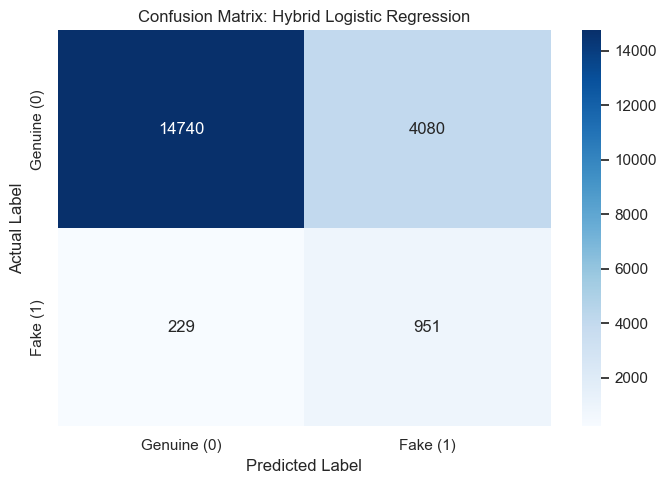

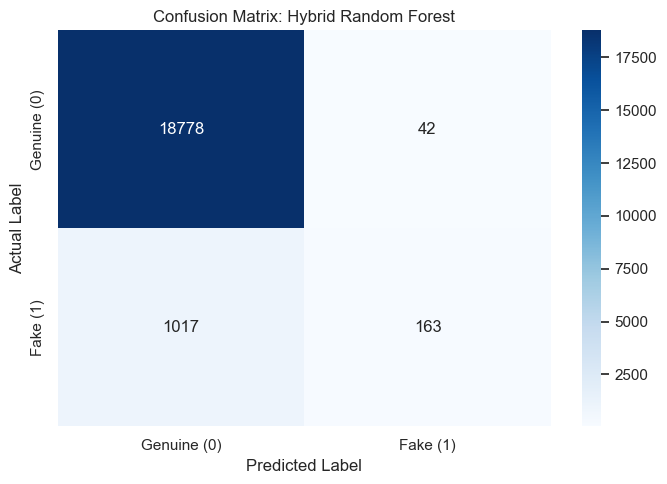

In [13]:
def save_confusion_matrix(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Genuine (0)", "Fake (1)"],
        yticklabels=["Genuine (0)", "Fake (1)"]
    )
    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

save_confusion_matrix(
    y_test,
    y_pred_lr,
    "Confusion Matrix: Hybrid Logistic Regression",
    "outputs/confusion_matrix_hybrid_logistic.png"
)

save_confusion_matrix(
    y_test,
    y_pred_rf,
    "Confusion Matrix: Hybrid Random Forest",
    "outputs/confusion_matrix_hybrid_random_forest.png"
)


## 11. Feature Importance: Random Forest

Feature importance is extracted from the Hybrid Random Forest model. This helps identify which hybrid features contribute most strongly to prediction.


,feature,importance
20,num__polarity_score,0.094020
19,num__subjectivity_score,0.085439
17,num__sentiment_score,0.073259
27,num__product_avg_rating,0.070508
2,num__star_rating,0.069842
15,num__readability_score,0.024736
4,num__review_length_words,0.023818
25,num__days_on_platform,0.023461
16,num__price_usd,0.022504
26,num__product_total_reviews,0.022007


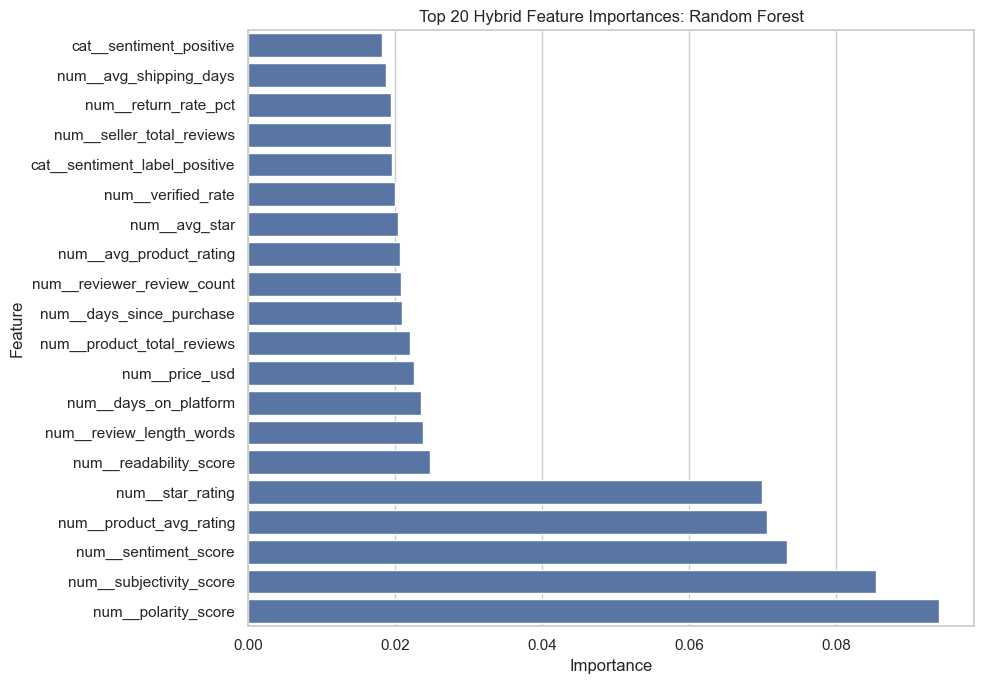

In [14]:
# Get feature names after preprocessing
preprocessor_fitted = hybrid_rf.named_steps["preprocess"]

feature_names = []

if numeric_features:
    feature_names.extend([f"num__{col}" for col in numeric_features])

if categorical_features:
    ohe = preprocessor_fitted.named_transformers_["cat"]
    cat_feature_names = ohe.get_feature_names_out(categorical_features)
    feature_names.extend([f"cat__{name}" for name in cat_feature_names])

importances = hybrid_rf.named_steps["model"].feature_importances_

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(feature_importance_df.head(20))

feature_importance_df.to_csv("outputs/feature_importance_hybrid_random_forest.csv", index=False)

plt.figure(figsize=(10, 7))
top_features = feature_importance_df.head(20).sort_values("importance", ascending=True)

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title("Top 20 Hybrid Feature Importances: Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("outputs/feature_importance_hybrid_random_forest.png", dpi=300)
plt.show()


## 12. Cross Validation on Training Set

This step provides an additional robustness check using 5 fold cross validation on the training set. The final reported performance should still be based on the held-out test set.


In [15]:

try:
    cv_lr = cross_val_score(
        hybrid_lr,
        X_train,
        y_train,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    cv_rf = cross_val_score(
        hybrid_rf,
        X_train,
        y_train,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    cv_results = pd.DataFrame({
        "model": ["Hybrid Logistic Regression", "Hybrid Random Forest"],
        "cv_f1_mean": [cv_lr.mean(), cv_rf.mean()],
        "cv_f1_std": [cv_lr.std(), cv_rf.std()]
    })

    display(cv_results.round(4))
    cv_results.to_csv("outputs/cross_validation_results.csv", index=False)

except Exception as e:
    print("Cross-validation skipped or failed:", e)


,model,cv_f1_mean,cv_f1_std
0,Hybrid Logistic Regression,0.3062,0.0057
1,Hybrid Random Forest,0.2179,0.0087


## 13. Error Analysis Samples

False positives and false negatives are saved for qualitative inspection. This can support the final analysis section of the report.


In [16]:
# Create a copy of test data for error analysis
test_results = X_test.copy()
test_results["actual_label"] = y_test.values
test_results["predicted_lr"] = y_pred_lr
test_results["predicted_rf"] = y_pred_rf

# Logistic Regression errors
lr_false_positives = test_results[
    (test_results["actual_label"] == 0) & (test_results["predicted_lr"] == 1)
]

lr_false_negatives = test_results[
    (test_results["actual_label"] == 1) & (test_results["predicted_lr"] == 0)
]

# Random Forest errors
rf_false_positives = test_results[
    (test_results["actual_label"] == 0) & (test_results["predicted_rf"] == 1)
]

rf_false_negatives = test_results[
    (test_results["actual_label"] == 1) & (test_results["predicted_rf"] == 0)
]

lr_false_positives.head(20).to_csv("outputs/hybrid_lr_false_positives_sample.csv", index=False)
lr_false_negatives.head(20).to_csv("outputs/hybrid_lr_false_negatives_sample.csv", index=False)
rf_false_positives.head(20).to_csv("outputs/hybrid_rf_false_positives_sample.csv", index=False)
rf_false_negatives.head(20).to_csv("outputs/hybrid_rf_false_negatives_sample.csv", index=False)

print("Error analysis samples saved.")
print("LR false positives:", len(lr_false_positives))
print("LR false negatives:", len(lr_false_negatives))
print("RF false positives:", len(rf_false_positives))
print("RF false negatives:", len(rf_false_negatives))


Error analysis samples saved.
LR false positives: 4080
LR false negatives: 229
RF false positives: 42
RF false negatives: 1017


## 14. Hybrid Model Summary

The hybrid model combines metadata, linguistic, product, and seller context features. Logistic Regression and Random Forest were trained using the same 80/20 stratified train/test split as the earlier phases.

The purpose of this phase is to test whether combining multiple signal types leads to improved fake review detection compared with using only metadata or only linguistic features.

Key outputs:
- `outputs/metrics.csv`
- `outputs/confusion_matrix_hybrid_logistic.png`
- `outputs/confusion_matrix_hybrid_random_forest.png`
- `outputs/feature_importance_hybrid_random_forest.csv`
- `outputs/feature_importance_hybrid_random_forest.png`

These outputs should be used in the final evaluation and report discussion.
